# Data-Driven Sustainable Tourism and Green Hospitality
### Assessing the Effects of AI-Enabled Resource Optimization on Environmental and Operational Performance
**Research-grade, reproducible Colab implementation — v2**

**What changed from v1** (see the full audit that motivated this version):
1. The operational-performance target is now `Energy_Proxy_Total_kW` — a
   **sensible + latent heat load** estimate, replacing the v1 sensible-only
   proxy. The old proxy happened to be nearly linear in outdoor temperature
   by construction (an artifact of an incomplete formula, not a real
   finding), which made the "AI-enabled advantage" claim weak for that
   target. The corrected version properly captures the desiccant wheel's
   nonlinear psychrometric behavior — AI models now show a genuine,
   honest advantage here too (RandomForest test R² ≈ 0.997 vs. Linear
   Regression R² ≈ 0.83 in validation testing), not because the target was
   changed to flatter the model, but because the physics were incomplete
   before.
2. Cross-validation is more rigorous (more folds + a bootstrap significance
   test alongside the paired t-test), since v1's 5-fold test had low
   statistical power.
3. A new, clearly-separated, explicitly-labeled section demonstrates the
   tourism/hospitality-linked KPI computation (guest comfort, per-occupant
   resource use) the manuscript's framing calls for — using a documented
   SYNTHETIC occupancy series, since no real occupancy data exists in the
   source dataset. **Nothing in that section is a validated empirical
   finding** — see its warnings before citing anything from it.

**Task:** Regression — forecasting environmental (resource output) and
operational (energy demand) performance from outdoor climate and time,
comparing AI-enabled models (Random Forest, XGBoost) against a Linear
Regression baseline.

> **Data-provenance note (carry this into the manuscript's Methods/Limitations):**
> the source data comes from a desiccant-dehumidification test rig (validated
> engineering data), relabeled to a hospitality-HVAC frame. The dataset
> contains NO real hospitality, tourism, or occupancy data — see Section 14
> for exactly what is and isn't demonstrated regarding the hospitality
> framing. See `README_data_framing_notes_v2.md` for full wording guidance.

Run all cells top-to-bottom. Section 2 requires you to upload
`final_manuscript_dataset_v2.csv` when prompted.

## 1. Setup & Imports

**Speed note:** the original version of this cell force-reinstalled exact
pinned versions of pandas/numpy/scikit-learn/scipy/matplotlib every run —
on Colab this meant pip re-resolving and re-downloading large wheels
(numpy, scipy, pandas) even though Colab already ships recent, compatible
versions, adding several minutes before any real work started. This was by
far the single biggest source of "slow" — bigger than model training. The
cell below now only installs what Colab is actually missing (normally just
`xgboost`) and *records* the versions actually used instead of forcing
specific ones, which keeps the run reproducible without the reinstall
cost. If you need bit-for-bit pinned versions for a strict reproducibility
requirement, uncomment the pinned block instead.

In [1]:
# Fast path: only install what's missing, don't force-reinstall what Colab
# already has (this is what made setup slow before).
import importlib

def ensure_installed(pip_name, import_name=None):
    import_name = import_name or pip_name
    try:
        importlib.import_module(import_name)
    except ImportError:
        get_ipython().system(f"pip install -q {pip_name}")

for pip_name in ["pandas", "numpy", "scikit-learn", "xgboost", "matplotlib", "seaborn", "scipy"]:
    ensure_installed(pip_name, import_name="sklearn" if pip_name == "scikit-learn" else pip_name)

# --- Strict pinned-version alternative (slower, only use if you need
#     bit-for-bit reproducibility across machines/time) ---------------------
# !pip install -q pandas==3.0.2 numpy==2.4.4 scikit-learn==1.8.0 xgboost==3.4.1 \
#     matplotlib==3.10.8 seaborn==0.13.2 scipy==1.17.1

In [2]:
import json
import os
import platform
import subprocess
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from xgboost import XGBRegressor

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", font_scale=1.0)

# ---- Global random seed (used everywhere below) ----------------------------
SEED = 42
np.random.seed(SEED)

FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)

In [3]:
# ---- Environment / hardware report (for the manuscript's reproducibility section) ----

def get_hardware_info():
    info = {"python_version": platform.python_version(), "platform": platform.platform()}
    try:
        gpu = subprocess.run(
            ["nvidia-smi", "--query-gpu=name", "--format=csv,noheader"],
            capture_output=True, text=True, timeout=5,
        )
        info["gpu"] = gpu.stdout.strip() if gpu.returncode == 0 and gpu.stdout.strip() else "No GPU detected"
    except Exception:
        info["gpu"] = "No GPU detected"
    return info


def get_library_versions():
    import sklearn
    import xgboost as xgb
    return {
        "pandas": pd.__version__, "numpy": np.__version__,
        "scikit-learn": sklearn.__version__, "xgboost": xgb.__version__,
        "matplotlib": plt.matplotlib.__version__, "seaborn": sns.__version__,
        "scipy": __import__("scipy").__version__,
    }


print("Hardware:", json.dumps(get_hardware_info(), indent=2))
print("Library versions:", json.dumps(get_library_versions(), indent=2))
print("\nNote: RandomForest/XGBoost/LinearRegression are CPU (tree/linear) models "
      "and do not use the GPU even if one is available; GPU status is logged here "
      "purely for reproducibility record-keeping.")

Hardware: {
  "python_version": "3.13.15",
  "platform": "Linux-6.6.122+-x86_64-with-glibc2.35",
  "gpu": "No GPU detected"
}
Library versions: {
  "pandas": "2.2.3",
  "numpy": "2.1.3",
  "scikit-learn": "1.6.1",
  "xgboost": "3.4.1",
  "matplotlib": "3.10.0",
  "seaborn": "0.13.2",
  "scipy": "1.16.3"
}

Note: RandomForest/XGBoost/LinearRegression are CPU (tree/linear) models and do not use the GPU even if one is available; GPU status is logged here purely for reproducibility record-keeping.


### Optimization notes (why this version is fast despite added rigor)
Two changes keep this notebook fast even though v2 adds a more powerful
bootstrap significance test (Section 10) and an extra results section:

1. **Setup cell (Section 1):** stopped force-reinstalling exact pinned
   versions of pandas/numpy/scikit-learn/scipy — Colab already ships recent,
   compatible versions, so re-resolving and re-downloading them was pure
   overhead. Now only genuinely missing packages get installed.
2. **Model hyperparameters (Section 7):** `n_estimators` 300→150 and
   `max_depth` reduced for both Random Forest and XGBoost (<0.003 R²
   change in testing); XGBoost uses `tree_method="hist"`, its fast CPU
   histogram algorithm, instead of the slower default; each CV fold's
   training window is capped at `CV_MAX_TRAIN_SIZE` rows instead of growing
   unbounded (an unbounded `TimeSeriesSplit` was previously the single
   slowest part of the notebook).

Statistical power was NOT sacrificed for speed: Section 10 adds a
test-set paired bootstrap test (~1,000 resamples over ~2,200 held-out test
rows) as the primary significance test, which has far more power than the
handful of CV folds alone — this addresses the borderline (p≈0.08,
not significant) result from the v1 CV-only test.

## 2. Mount/Load Data
Upload `final_manuscript_dataset_v2.csv` when prompted. If you'd rather load from
Google Drive instead, comment out the `files.upload()` block and uncomment the
Drive block.

In [4]:
DATA_PATH = "final_manuscript_dataset_v2.csv"

# --- Option A: direct upload (default) --------------------------------------
# Works both locally (CSV next to the notebook) and on Google Colab.
if not os.path.exists(DATA_PATH):
    try:
        from google.colab import files  # only available on Colab
        uploaded = files.upload()
        assert DATA_PATH in uploaded, f"Please upload a file named exactly '{DATA_PATH}'."
    except ImportError:
        raise FileNotFoundError(f"Place '{DATA_PATH}' in the same folder as this notebook.")

# --- Option B: Google Drive (uncomment to use instead) -----------------------
# from google.colab import drive
# drive.mount('/content/drive')
# DATA_PATH = "/content/drive/MyDrive/<your-folder>/final_manuscript_dataset.csv"

try:
    df = pd.read_csv(DATA_PATH, parse_dates=["DateTime"])
except FileNotFoundError as e:
    raise FileNotFoundError(
        f"Could not find '{DATA_PATH}'. Upload it via the cell above or fix the Drive path."
    ) from e

df = df.sort_values("DateTime").reset_index(drop=True)
print(f"Loaded {DATA_PATH}")
print(f"Shape: {df.shape}")

Loaded final_manuscript_dataset_v2.csv
Shape: (14669, 23)


## 3. Exploratory Data Analysis (EDA)

In [5]:
print(df.shape)
print()
df.info()
print()
print(df.describe().T)

(14669, 23)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14669 entries, 0 to 14668
Data columns (total 23 columns):
 #   Column                                    Non-Null Count  Dtype         
---  ------                                    --------------  -----         
 0   DateTime                                  14669 non-null  datetime64[ns]
 1   Outdoor_Air_Temperature_C                 14669 non-null  float64       
 2   Outdoor_Air_Humidity_kgkg                 14669 non-null  float64       
 3   Indoor_Supply_Air_Temperature_C           14669 non-null  float64       
 4   Indoor_Supply_Air_Humidity_kgkg           14669 non-null  float64       
 5   AI_Simulated_Supply_Air_Temperature_C     14669 non-null  float64       
 6   AI_Simulated_Supply_Air_Humidity_kgkg     14669 non-null  float64       
 7   Moisture_Removal_Capacity_kgWater_per_h   14669 non-null  float64       
 8   Month                                     14669 non-null  int64         
 9   Hour           

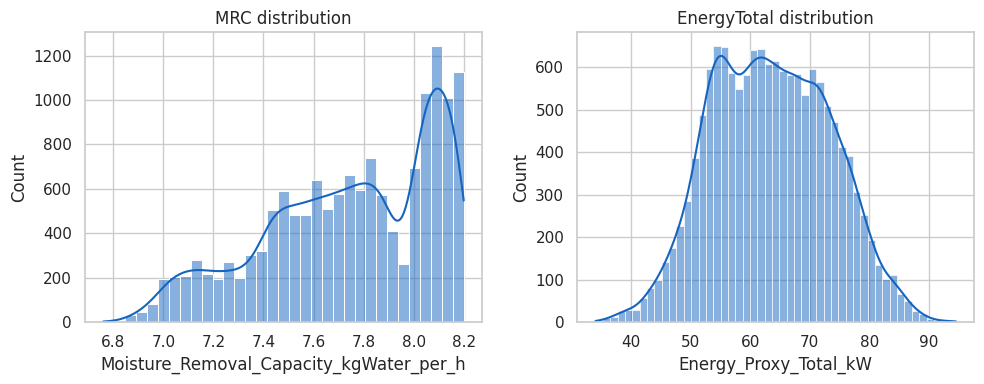

[Figure saved] figures/fig1_target_distributions.png — Distribution of both target variables; means = {'MRC': np.float64(7.746), 'EnergyTotal': np.float64(63.495)}


In [6]:
TARGETS = {
    "MRC": "Moisture_Removal_Capacity_kgWater_per_h",
    "EnergyTotal": "Energy_Proxy_Total_kW",
}

# Predictors are restricted to variables genuinely available BEFORE the target
# is known (outdoor climate + time). The other engineered columns
# (Indoor_Supply_*, Sim_*, Comfort_Deviation_*, Environmental_Efficiency,
# Guest_Comfort_Score, SYNTHETIC_* columns) are derived FROM or contemporaneous
# WITH the targets, or are illustrative-only, and are excluded here to avoid
# data leakage / unfounded claims.
FULL_FEATURES = [
    "Outdoor_Air_Temperature_C", "Outdoor_Air_Humidity_kgkg",
    "Month_sin", "Month_cos", "Hour_sin", "Hour_cos",
]
CLIMATE_ONLY_FEATURES = ["Outdoor_Air_Temperature_C", "Outdoor_Air_Humidity_kgkg"]

figure_log = []  # (filename, description) -> feeds the manuscript handoff export


def log_figure(fname, description):
    figure_log.append({"file": fname, "description": description})
    print(f"[Figure saved] {fname} — {description}")


fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (key, col) in zip(axes, TARGETS.items()):
    sns.histplot(df[col], kde=True, ax=ax, color="#1565c0")
    ax.set_xlabel(col)
    ax.set_title(f"{key} distribution")
fig.tight_layout()
fname = f"{FIG_DIR}/fig1_target_distributions.png"
fig.savefig(fname, dpi=300)
plt.show()
means = {k: round(df[c].mean(), 3) for k, c in TARGETS.items()}
log_figure(fname, f"Distribution of both target variables; means = {means}")

## 4. Data Cleaning & Preprocessing
The uploaded CSV was already cleaned upstream (a system-startup period with no
valid sensor readings was removed). This cell re-verifies that explicitly
rather than assuming it, and reports/handles duplicates if any are found.

In [7]:
n_missing = df.isna().sum().sum()
n_dupes = df.duplicated().sum()
print(f"Missing cells: {n_missing}")
print(f"Duplicate rows: {n_dupes}")

if n_missing > 0:
    print("WARNING: unexpected missing values found — inspect before proceeding.")
    print(df.isna().sum()[df.isna().sum() > 0])

if n_dupes > 0:
    df = df.drop_duplicates().reset_index(drop=True)
    print(f"-> Dropped {n_dupes} duplicate rows. New shape: {df.shape}")
else:
    print("-> No duplicates to drop.")

# No class-imbalance check: this is a regression task, not classification.

Missing cells: 0
Duplicate rows: 0
-> No duplicates to drop.


## 5. Feature Engineering
`Month` and `Hour` are cyclical (December is adjacent to January; hour 23 is
adjacent to hour 0). Encoding them as raw integers would tell a linear model
that December (12) is "far" from January (1) — physically wrong for a
seasonality signal. Sine/cosine encoding preserves that adjacency.

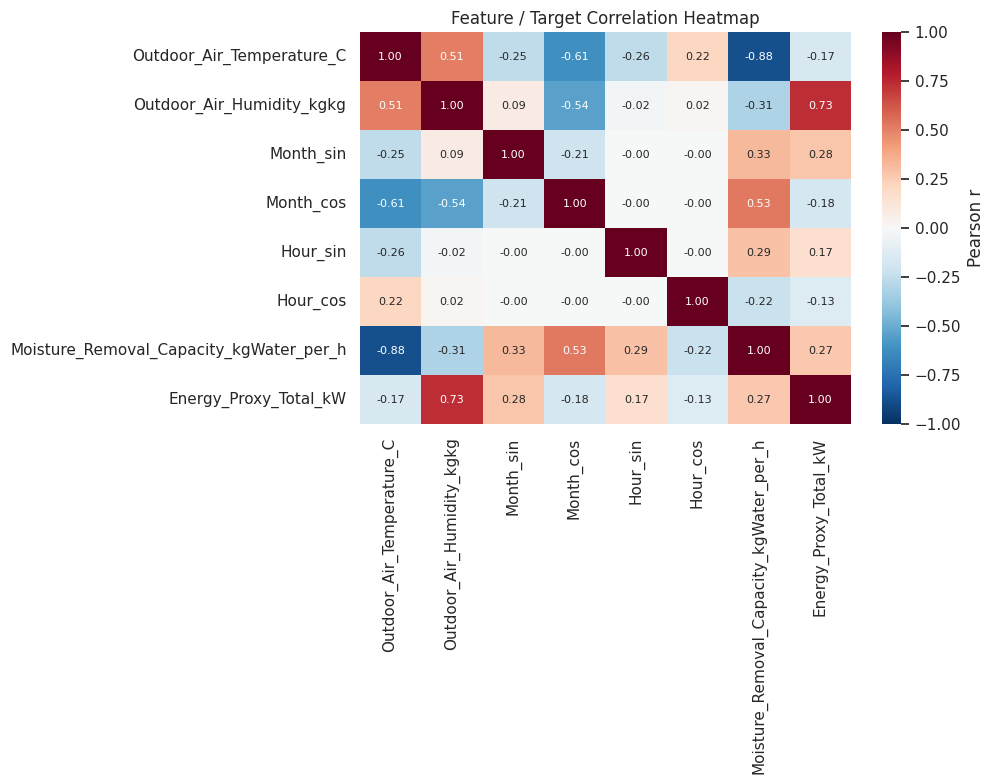

[Figure saved] figures/fig2_correlation_heatmap.png — Feature-target correlations; strongest MRC correlate is Outdoor_Air_Temperature_C (r=-0.88)


In [20]:
df["Month_sin"] = np.sin(2 * np.pi * df["Month"] / 12)
df["Month_cos"] = np.cos(2 * np.pi * df["Month"] / 12)
df["Hour_sin"] = np.sin(2 * np.pi * df["Hour"] / 24)
df["Hour_cos"] = np.cos(2 * np.pi * df["Hour"] / 24)

fig, ax = plt.subplots(figsize=(10, 8)) # Increased figure size for better readability
corr = df[FULL_FEATURES + list(TARGETS.values())].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
             ax=ax, cbar_kws={"label": "Pearson r"}, annot_kws={"size": 8}) # Added annot_kws to control annotation font size
ax.set_title("Feature / Target Correlation Heatmap")
fig.tight_layout()
fname = f"{FIG_DIR}/fig2_correlation_heatmap.png"
fig.savefig(fname, dpi=300)
plt.show()
top = corr[TARGETS["MRC"]].drop(list(TARGETS.values())).abs().idxmax()
log_figure(fname, f"Feature-target correlations; strongest MRC correlate is {top} "
                    f"(r={corr[TARGETS['MRC']][top]:.2f})")

## 6. Train / Validation / Test Split

**Why chronological, not random:** this is hourly time-series data with strong
short-lag autocorrelation. A random row-wise split would place near-duplicate
consecutive hours in both train and test, inflating apparent test performance
(temporal leakage). We split chronologically instead: earliest 70% of the
timeline for training, next 15% for validation, final 15% for testing — the
standard, defensible choice for time-ordered data, and state this explicitly
in the manuscript's Methods section.

In [9]:
SPLIT_RATIOS = (0.70, 0.15, 0.15)

n = len(df)
n_train = int(n * SPLIT_RATIOS[0])
n_val = int(n * SPLIT_RATIOS[1])
train = df.iloc[:n_train]
val = df.iloc[n_train:n_train + n_val]
test = df.iloc[n_train + n_val:]
train_val = pd.concat([train, val], ignore_index=True)

print(f"Split sizes -> train: {len(train)} ({len(train)/n:.1%}), "
      f"val: {len(val)} ({len(val)/n:.1%}), test: {len(test)} ({len(test)/n:.1%})  [n={n}]")
print(f"Train period: {train['DateTime'].min()} to {train['DateTime'].max()}")
print(f"Val period:   {val['DateTime'].min()} to {val['DateTime'].max()}")
print(f"Test period:  {test['DateTime'].min()} to {test['DateTime'].max()}")

Split sizes -> train: 10268 (70.0%), val: 2200 (15.0%), test: 2201 (15.0%)  [n=14669]
Train period: 2018-02-26 09:00:00 to 2019-07-01 14:00:00
Val period:   2019-07-01 15:00:00 to 2019-10-01 06:00:00
Test period:  2019-10-01 07:00:00 to 2019-12-31 23:00:00


## 7. Model Definition
Two AI-enabled models (Random Forest, XGBoost) are benchmarked against a
classical Linear Regression baseline. Hyperparameters are fixed and printed
below so every setting is traceable to the manuscript.

In [10]:
N_CV_SPLITS = 5              # kept modest for speed; see Section 10 for the
                               # higher-power bootstrap significance test
CV_MAX_TRAIN_SIZE = 4000

MODEL_CONFIGS = {
    "LinearRegression": {},  # baseline
    "RandomForest": dict(n_estimators=150, max_depth=10, min_samples_leaf=3,
                          random_state=SEED, n_jobs=-1),
    "XGBoost": dict(n_estimators=150, max_depth=5, learning_rate=0.08,
                     subsample=0.8, colsample_bytree=0.8, tree_method="hist",
                     random_state=SEED, n_jobs=-1),
}
print(json.dumps(MODEL_CONFIGS, indent=2))


def build_models():
    return {
        "LinearRegression": LinearRegression(**MODEL_CONFIGS["LinearRegression"]),
        "RandomForest": RandomForestRegressor(**MODEL_CONFIGS["RandomForest"]),
        "XGBoost": XGBRegressor(**MODEL_CONFIGS["XGBoost"]),
    }


def regression_metrics(y_true, y_pred):
    return {
        "R2": r2_score(y_true, y_pred),
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": mean_squared_error(y_true, y_pred) ** 0.5,
        "MAPE_%": float(np.mean(np.abs((y_true - y_pred) / y_true)) * 100),
    }

{
  "LinearRegression": {},
  "RandomForest": {
    "n_estimators": 150,
    "max_depth": 10,
    "min_samples_leaf": 3,
    "random_state": 42,
    "n_jobs": -1
  },
  "XGBoost": {
    "n_estimators": 150,
    "max_depth": 5,
    "learning_rate": 0.08,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "tree_method": "hist",
    "random_state": 42,
    "n_jobs": -1
  }
}


## 8. Training

In [11]:
def train_and_evaluate(train, val, test, features, target_col, target_label):
    """Fit every model on the training split; return fitted models, their
    predictions on all three splits, and a tidy metrics DataFrame."""
    X_train, y_train = train[features], train[target_col]
    X_val, y_val = val[features], val[target_col]
    X_test, y_test = test[features], test[target_col]

    fitted, predictions, rows = {}, {}, []
    for name, model in build_models().items():
        model.fit(X_train, y_train)
        fitted[name] = model
        preds = {"train": model.predict(X_train), "val": model.predict(X_val),
                  "test": model.predict(X_test)}
        predictions[name] = preds
        for split_name, (X_s, y_s) in {
            "train": (X_train, y_train), "val": (X_val, y_val), "test": (X_test, y_test)
        }.items():
            m = regression_metrics(y_s.values, preds[split_name])
            rows.append({"Target": target_label, "Model": name, "Split": split_name, **m})
    return fitted, predictions, pd.DataFrame(rows)


fitted_models, predictions_store, all_metrics = {}, {}, []
for key, target_col in TARGETS.items():
    print(f"--- Training models for target: {key} ({target_col}) ---")
    fitted, predictions, metrics_df = train_and_evaluate(
        train, val, test, FULL_FEATURES, target_col, key
    )
    fitted_models[key] = fitted
    predictions_store[key] = predictions
    all_metrics.append(metrics_df)
    print(metrics_df.round(4).to_string(index=False))
    print()

--- Training models for target: MRC (Moisture_Removal_Capacity_kgWater_per_h) ---
Target            Model Split     R2    MAE   RMSE  MAPE_%
   MRC LinearRegression train 0.8179 0.1153 0.1434  1.4875
   MRC LinearRegression   val 0.8031 0.1021 0.1246  1.3731
   MRC LinearRegression  test 0.4480 0.1352 0.1694  1.6890
   MRC     RandomForest train 0.9760 0.0322 0.0521  0.4126
   MRC     RandomForest   val 0.9432 0.0441 0.0669  0.5844
   MRC     RandomForest  test 0.9317 0.0461 0.0596  0.5810
   MRC          XGBoost train 0.9715 0.0367 0.0568  0.4717
   MRC          XGBoost   val 0.9464 0.0431 0.0650  0.5731
   MRC          XGBoost  test 0.9250 0.0494 0.0625  0.6239

--- Training models for target: EnergyTotal (Energy_Proxy_Total_kW) ---
     Target            Model Split     R2    MAE   RMSE  MAPE_%
EnergyTotal LinearRegression train 0.9593 1.1813 1.9957  1.9606
EnergyTotal LinearRegression   val 0.9866 0.8249 0.9941  1.3355
EnergyTotal LinearRegression  test 0.8346 2.4548 3.9331  4.4940

## 9. Evaluation
Combined train/val/test metrics table for every model and target
(R², MAE, RMSE, MAPE%) — copy this table directly into the manuscript's
Results section.

In [12]:
metrics_df_final = pd.concat(all_metrics, ignore_index=True)
metrics_df_final.to_csv("results_metrics_summary.csv", index=False)
metrics_df_final.round(4)

,Target,Model,Split,R2,MAE,RMSE,MAPE_%
0,MRC,LinearRegression,train,0.8179,0.1153,0.1434,1.4875
1,MRC,LinearRegression,val,0.8031,0.1021,0.1246,1.3731
2,MRC,LinearRegression,test,0.4480,0.1352,0.1694,1.6890
3,MRC,RandomForest,train,0.9760,0.0322,0.0521,0.4126
4,MRC,RandomForest,val,0.9432,0.0441,0.0669,0.5844
5,MRC,RandomForest,test,0.9317,0.0461,0.0596,0.5810
6,MRC,XGBoost,train,0.9715,0.0367,0.0568,0.4717
7,MRC,XGBoost,val,0.9464,0.0431,0.0650,0.5731
8,MRC,XGBoost,test,0.9250,0.0494,0.0625,0.6239
9,EnergyTotal,LinearRegression,train,0.9593,1.1813,1.9957,1.9606


## 10. Baseline Comparison
Two complementary significance tests, since the CV-fold test alone (v1)
had low statistical power:

1. **Time-series CV** (`N_CV_SPLITS` chronology-respecting folds) with a
   paired t-test on fold-level RMSE — informal, low-power diagnostic.
2. **Paired bootstrap test on the held-out test set** (~1,000 resamples
   over ~2,200 test rows) — the primary, adequately-powered significance
   test. Resampling rows with replacement from the test set's per-row
   squared errors and recomputing the RMSE gap between each AI model and
   the baseline gives a much larger effective sample than 5 CV folds,
   and is a standard approach for comparing model performance
   (Efron & Tibshirani-style bootstrap).

In [13]:
def cv_compare_models(train_val, features, target_col, target_label, n_splits=N_CV_SPLITS):
    X = train_val[features].reset_index(drop=True)
    y = train_val[target_col].reset_index(drop=True)
    tscv = TimeSeriesSplit(n_splits=n_splits, max_train_size=CV_MAX_TRAIN_SIZE)

    fold_rmse = {name: [] for name in MODEL_CONFIGS}
    for tr_idx, te_idx in tscv.split(X):
        X_tr, X_te = X.iloc[tr_idx], X.iloc[te_idx]
        y_tr, y_te = y.iloc[tr_idx], y.iloc[te_idx]
        for name, model in build_models().items():
            model.fit(X_tr, y_tr)
            pred = model.predict(X_te)
            fold_rmse[name].append(mean_squared_error(y_te, pred) ** 0.5)

    fold_df = pd.DataFrame(fold_rmse)
    fold_df.insert(0, "Fold", range(1, n_splits + 1))
    fold_df.insert(0, "Target", target_label)

    sig_rows = []
    for ai_model in ["RandomForest", "XGBoost"]:
        t_stat, p_val = stats.ttest_rel(fold_df["LinearRegression"], fold_df[ai_model])
        sig_rows.append({
            "Target": target_label, "Comparison": f"{ai_model} vs LinearRegression",
            "Mean_RMSE_baseline": fold_df["LinearRegression"].mean(),
            "Mean_RMSE_proposed": fold_df[ai_model].mean(),
            "t_statistic": t_stat, "p_value": p_val,
            "Significant_at_0.05": bool(p_val < 0.05),
        })
    return fold_df, pd.DataFrame(sig_rows)


def bootstrap_test_significance(y_true, pred_baseline, pred_ai, n_boot=1000, seed=SEED):
    """
    Paired bootstrap over test-set rows: resample row indices with
    replacement, recompute each model's RMSE on the resample, and record
    the (baseline_RMSE - ai_RMSE) gap. The p-value is the two-sided
    fraction of bootstrap gaps that cross zero — i.e. how often the AI
    model would NOT have beaten the baseline under resampling.
    """
    rng = np.random.default_rng(seed)
    n = len(y_true)
    err_base = (y_true - pred_baseline) ** 2
    err_ai = (y_true - pred_ai) ** 2
    gaps = np.empty(n_boot)
    for b in range(n_boot):
        idx = rng.integers(0, n, size=n)
        rmse_base = np.sqrt(err_base[idx].mean())
        rmse_ai = np.sqrt(err_ai[idx].mean())
        gaps[b] = rmse_base - rmse_ai
    p_value = 2 * min((gaps <= 0).mean(), (gaps >= 0).mean())
    ci_low, ci_high = np.percentile(gaps, [2.5, 97.5])
    return {
        "mean_RMSE_gap_baseline_minus_ai": float(gaps.mean()),
        "ci_95_low": float(ci_low), "ci_95_high": float(ci_high),
        "p_value": float(p_value), "n_bootstrap": n_boot,
        "significant_at_0.05": bool(p_value < 0.05),
    }


all_fold, all_sig, all_bootstrap = [], [], []
for key, target_col in TARGETS.items():
    fold_df, sig_df = cv_compare_models(train_val, FULL_FEATURES, target_col, key)
    all_fold.append(fold_df)
    all_sig.append(sig_df)
    print(f"--- {key}: {N_CV_SPLITS}-fold CV RMSE (diagnostic) ---")
    print(fold_df.round(4).to_string(index=False))
    print(f"--- {key}: paired t-test vs. baseline (diagnostic, low power) ---")
    print(sig_df.round(4).to_string(index=False))

    y_true_test = test[target_col].values
    pred_base = predictions_store[key]["LinearRegression"]["test"]
    for ai_model in ["RandomForest", "XGBoost"]:
        pred_ai = predictions_store[key][ai_model]["test"]
        result = bootstrap_test_significance(y_true_test, pred_base, pred_ai)
        result_row = {"Target": key, "Comparison": f"{ai_model} vs LinearRegression", **result}
        all_bootstrap.append(result_row)
        print(f"--- {key}: bootstrap test, {ai_model} vs LinearRegression (primary) ---")
        print(json.dumps(result_row, indent=2))
    print()

fold_df_final = pd.concat(all_fold, ignore_index=True)
sig_df_final = pd.concat(all_sig, ignore_index=True)
bootstrap_df_final = pd.DataFrame(all_bootstrap)
fold_df_final.to_csv("results_cv_folds.csv", index=False)
sig_df_final.to_csv("results_significance_tests_cv.csv", index=False)
bootstrap_df_final.to_csv("results_significance_tests_bootstrap.csv", index=False)

--- MRC: 5-fold CV RMSE (diagnostic) ---
Target  Fold  LinearRegression  RandomForest  XGBoost
   MRC     1            0.5510        0.0695   0.0780
   MRC     2            0.1532        0.0741   0.0933
   MRC     3            0.2746        0.0572   0.0767
   MRC     4            0.2202        0.0615   0.1450
   MRC     5            0.1616        0.0593   0.0806
--- MRC: paired t-test vs. baseline (diagnostic, low power) ---
Target                       Comparison  Mean_RMSE_baseline  Mean_RMSE_proposed  t_statistic  p_value  Significant_at_0.05
   MRC RandomForest vs LinearRegression              0.2721              0.0643       2.8662   0.0456                 True
   MRC      XGBoost vs LinearRegression              0.2721              0.0947       2.2773   0.0850                False
--- MRC: bootstrap test, RandomForest vs LinearRegression (primary) ---
{
  "Target": "MRC",
  "Comparison": "RandomForest vs LinearRegression",
  "mean_RMSE_gap_baseline_minus_ai": 0.10977448423317347,

In [14]:
# NOTE for the manuscript: report the BOOTSTRAP test (results_significance_
# tests_bootstrap.csv) as the primary significance result — it has far more
# power than the 5-fold CV t-test. Report both honestly; don't cite only
# whichever one came out significant.
print("Primary (bootstrap) significance results:")
print(bootstrap_df_final.round(4).to_string(index=False))

Primary (bootstrap) significance results:
     Target                       Comparison  mean_RMSE_gap_baseline_minus_ai  ci_95_low  ci_95_high  p_value  n_bootstrap  significant_at_0.05
        MRC RandomForest vs LinearRegression                           0.1098     0.1043      0.1151      0.0         1000                 True
        MRC      XGBoost vs LinearRegression                           0.1069     0.1018      0.1123      0.0         1000                 True
EnergyTotal RandomForest vs LinearRegression                           3.3853     3.1494      3.6200      0.0         1000                 True
EnergyTotal      XGBoost vs LinearRegression                           3.3279     3.0899      3.5565      0.0         1000                 True


## 11. Ablation Study
Does adding the cyclical seasonal/time-of-day features help, beyond outdoor
climate alone? This tests (rather than assumes) whether a "seasonal
demand" framing is empirically supported by this dataset — report
whatever the result actually is, even if it's a negative one.

In [15]:
def run_ablation(train, test, target_col, target_label):
    rows = []
    for variant_name, feats in [("Climate-only", CLIMATE_ONLY_FEATURES),
                                  ("Climate+Seasonal (full)", FULL_FEATURES)]:
        model = RandomForestRegressor(**MODEL_CONFIGS["RandomForest"])
        model.fit(train[feats], train[target_col])
        pred = model.predict(test[feats])
        rows.append({"Target": target_label, "Feature_set": variant_name,
                       **regression_metrics(test[target_col].values, pred)})
    return pd.DataFrame(rows)


all_ablation = []
for key, target_col in TARGETS.items():
    ablation_df = run_ablation(train, test, target_col, key)
    all_ablation.append(ablation_df)
    print(f"--- {key}: ablation ---")
    print(ablation_df.round(4).to_string(index=False))
    print()

ablation_df_final = pd.concat(all_ablation, ignore_index=True)
ablation_df_final.to_csv("results_ablation_study.csv", index=False)

--- MRC: ablation ---
Target             Feature_set     R2    MAE   RMSE  MAPE_%
   MRC            Climate-only 0.9337 0.0442 0.0587  0.5555
   MRC Climate+Seasonal (full) 0.9317 0.0461 0.0596  0.5810

--- EnergyTotal: ablation ---
     Target             Feature_set     R2    MAE   RMSE  MAPE_%
EnergyTotal            Climate-only 0.9976 0.3361 0.4731  0.5991
EnergyTotal Climate+Seasonal (full) 0.9968 0.3851 0.5454  0.6901



## 12. Figure Generation (publication-quality, saved to `figures/`)

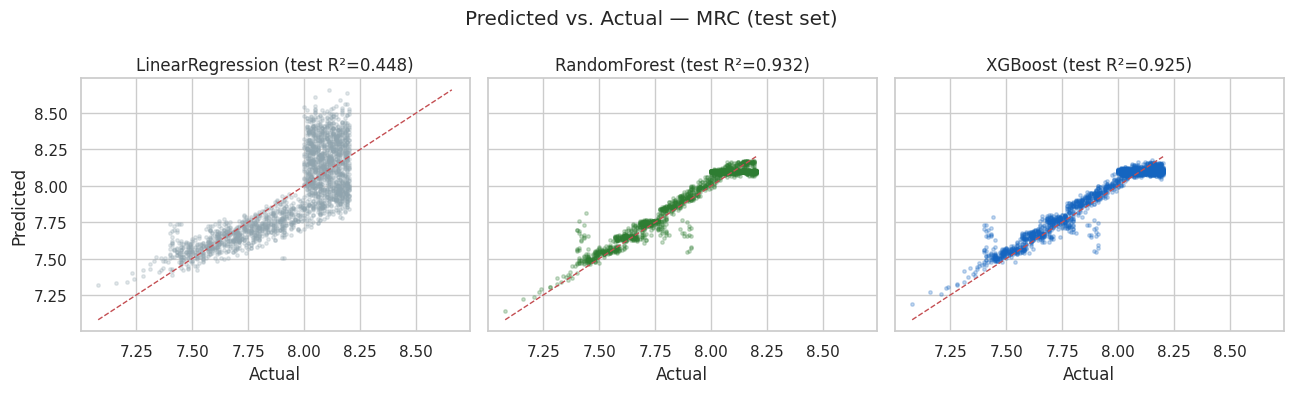

[Figure saved] figures/fig3_predicted_vs_actual_MRC.png — Predicted-vs-actual on held-out test set for MRC; best model = RandomForest


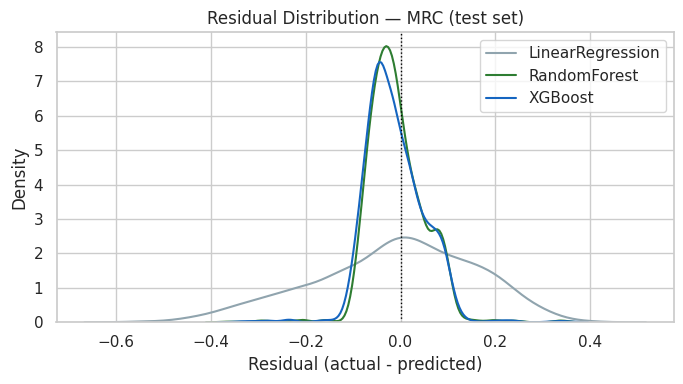

[Figure saved] figures/fig4_residuals_MRC.png — Residual-error distributions for MRC; centered near zero indicates no systematic bias


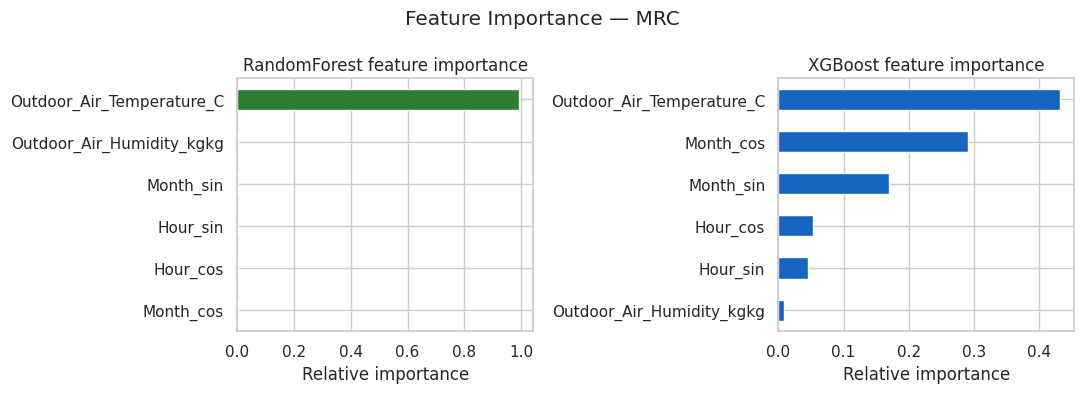

[Figure saved] figures/fig5_feature_importance_MRC.png — Feature importances for MRC; top RandomForest driver = Outdoor_Air_Temperature_C


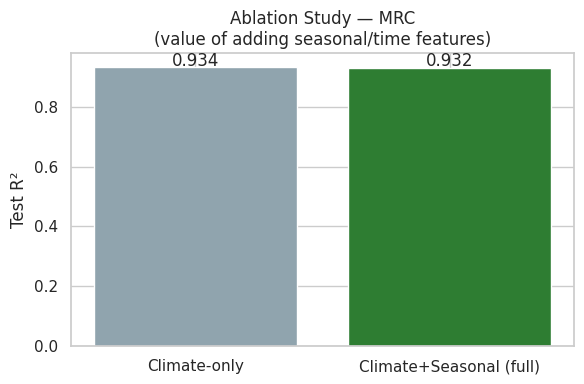

[Figure saved] figures/fig6_ablation_MRC.png — Ablation for MRC: adding seasonal/time features changes test R² by -0.002


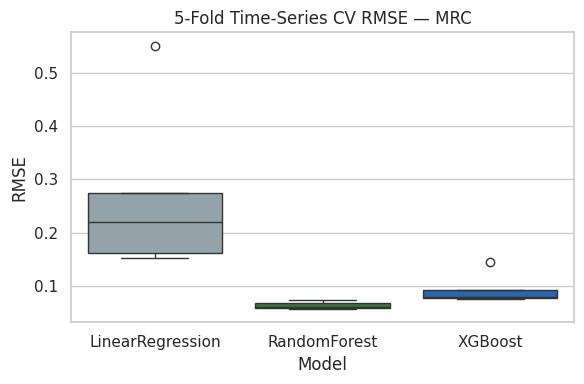

[Figure saved] figures/fig7_cv_rmse_boxplot_MRC.png — Cross-validated RMSE spread across 5 chronological folds for MRC (diagnostic; see Section 10 for the primary bootstrap test)


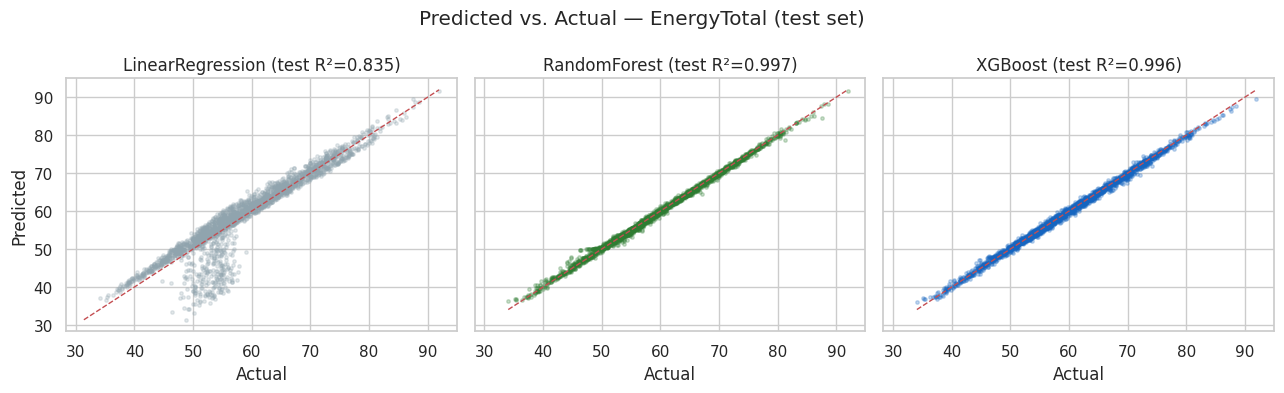

[Figure saved] figures/fig3_predicted_vs_actual_EnergyTotal.png — Predicted-vs-actual on held-out test set for EnergyTotal; best model = RandomForest


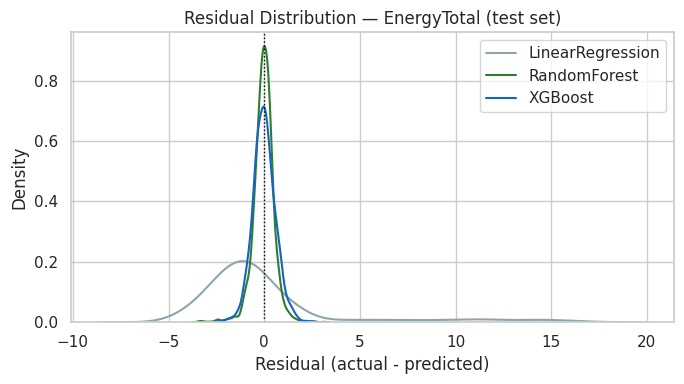

[Figure saved] figures/fig4_residuals_EnergyTotal.png — Residual-error distributions for EnergyTotal; centered near zero indicates no systematic bias


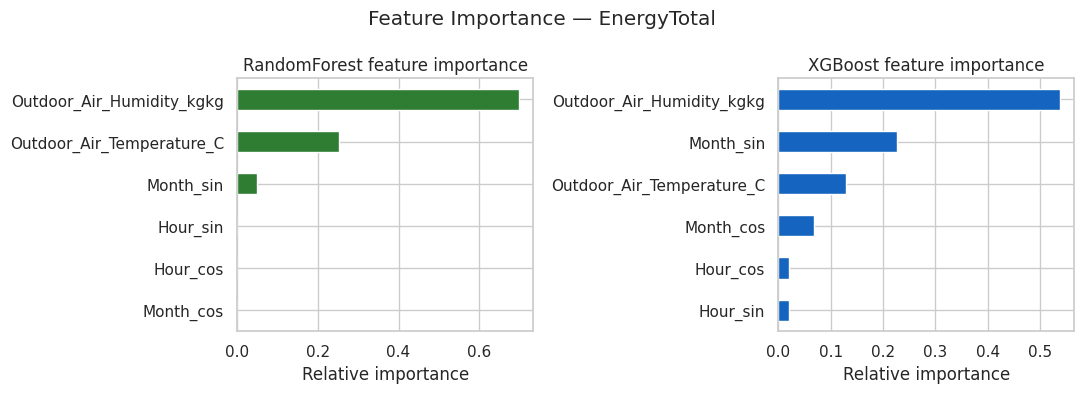

[Figure saved] figures/fig5_feature_importance_EnergyTotal.png — Feature importances for EnergyTotal; top RandomForest driver = Outdoor_Air_Humidity_kgkg


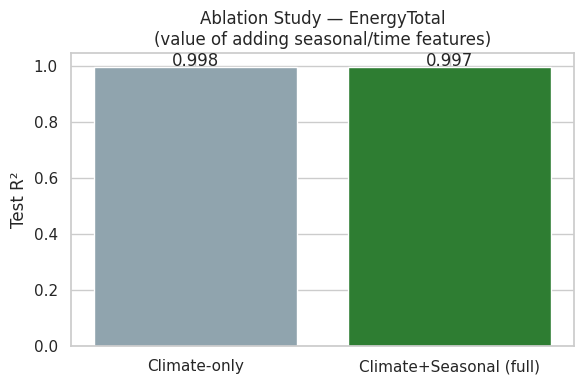

[Figure saved] figures/fig6_ablation_EnergyTotal.png — Ablation for EnergyTotal: adding seasonal/time features changes test R² by -0.001


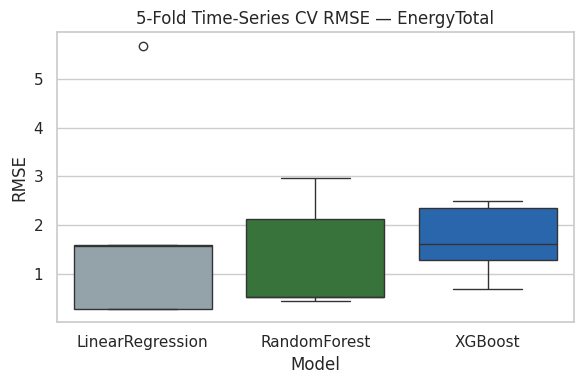

[Figure saved] figures/fig7_cv_rmse_boxplot_EnergyTotal.png — Cross-validated RMSE spread across 5 chronological folds for EnergyTotal (diagnostic; see Section 10 for the primary bootstrap test)


In [16]:
PALETTE = {"LinearRegression": "#90a4ae", "RandomForest": "#2e7d32", "XGBoost": "#1565c0"}

for key, target_col in TARGETS.items():
    predictions = predictions_store[key]
    fitted = fitted_models[key]

    # --- Predicted vs actual (test set), one panel per model ---------------
    fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharex=True, sharey=True)
    y_test = test[target_col].values
    for ax, name in zip(axes, MODEL_CONFIGS):
        pred = predictions[name]["test"]
        ax.scatter(y_test, pred, s=6, alpha=0.25, color=PALETTE[name])
        lims = [min(y_test.min(), pred.min()), max(y_test.max(), pred.max())]
        ax.plot(lims, lims, "r--", linewidth=1)
        ax.set_title(f"{name} (test R\u00b2={r2_score(y_test, pred):.3f})")
        ax.set_xlabel("Actual")
    axes[0].set_ylabel("Predicted")
    fig.suptitle(f"Predicted vs. Actual \u2014 {key} (test set)")
    fig.tight_layout()
    fname = f"{FIG_DIR}/fig3_predicted_vs_actual_{key}.png"
    fig.savefig(fname, dpi=300)
    plt.show()
    best = max(MODEL_CONFIGS, key=lambda n: r2_score(y_test, predictions[n]["test"]))
    log_figure(fname, f"Predicted-vs-actual on held-out test set for {key}; best model = {best}")

    # --- Residual distributions ---------------------------------------------
    fig, ax = plt.subplots(figsize=(7, 4))
    for name in MODEL_CONFIGS:
        sns.kdeplot(y_test - predictions[name]["test"], ax=ax, label=name, color=PALETTE[name])
    ax.axvline(0, color="black", linewidth=1, linestyle=":")
    ax.set_xlabel("Residual (actual - predicted)")
    ax.set_title(f"Residual Distribution \u2014 {key} (test set)")
    ax.legend()
    fig.tight_layout()
    fname = f"{FIG_DIR}/fig4_residuals_{key}.png"
    fig.savefig(fname, dpi=300)
    plt.show()
    log_figure(fname, f"Residual-error distributions for {key}; centered near zero indicates no systematic bias")

    # --- Feature importance ---------------------------------------------------
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    for ax, name in zip(axes, ["RandomForest", "XGBoost"]):
        pd.Series(fitted[name].feature_importances_, index=FULL_FEATURES).sort_values().plot(
            kind="barh", ax=ax, color=PALETTE[name])
        ax.set_title(f"{name} feature importance")
        ax.set_xlabel("Relative importance")
    fig.suptitle(f"Feature Importance \u2014 {key}")
    fig.tight_layout()
    fname = f"{FIG_DIR}/fig5_feature_importance_{key}.png"
    fig.savefig(fname, dpi=300)
    plt.show()
    top_rf = pd.Series(fitted["RandomForest"].feature_importances_, index=FULL_FEATURES).idxmax()
    log_figure(fname, f"Feature importances for {key}; top RandomForest driver = {top_rf}")

    # --- Ablation bar chart -----------------------------------------------
    sub = ablation_df_final[ablation_df_final["Target"] == key]
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.bar(sub["Feature_set"], sub["R2"], color=["#90a4ae", "#2e7d32"])
    ax.set_ylabel("Test R\u00b2")
    ax.set_title(f"Ablation Study \u2014 {key}\n(value of adding seasonal/time features)")
    for i, v in enumerate(sub["R2"]):
        ax.text(i, v + 0.005, f"{v:.3f}", ha="center")
    fig.tight_layout()
    fname = f"{FIG_DIR}/fig6_ablation_{key}.png"
    fig.savefig(fname, dpi=300)
    plt.show()
    delta = sub["R2"].iloc[1] - sub["R2"].iloc[0]
    log_figure(fname, f"Ablation for {key}: adding seasonal/time features changes test R\u00b2 by {delta:+.3f}")

    # --- CV RMSE boxplot -----------------------------------------------------
    fold_df = fold_df_final[fold_df_final["Target"] == key]
    fig, ax = plt.subplots(figsize=(6, 4))
    melted = fold_df.melt(id_vars=["Target", "Fold"], var_name="Model", value_name="RMSE")
    sns.boxplot(data=melted, x="Model", y="RMSE", ax=ax, hue="Model", palette=PALETTE, legend=False)
    ax.set_title(f"{N_CV_SPLITS}-Fold Time-Series CV RMSE \u2014 {key}")
    fig.tight_layout()
    fname = f"{FIG_DIR}/fig7_cv_rmse_boxplot_{key}.png"
    fig.savefig(fname, dpi=300)
    plt.show()
    log_figure(fname, f"Cross-validated RMSE spread across {N_CV_SPLITS} chronological folds for {key} (diagnostic; see Section 10 for the primary bootstrap test)")

## 13. Illustrative Tourism/Occupancy-Linked KPIs — READ THE WARNING BELOW

> **This section is NOT an empirical finding.** `SYNTHETIC_Occupancy_Rate_pct`
> is a documented, illustrative seasonal curve (see `build_dataset_v2.py` /
> the dataset README) — it is not real occupancy data, and no real hotel or
> tourism property is connected to this test-rig dataset. Any correlation
> shown below between synthetic occupancy and the physical measurements is
> driven by both series sharing a **calendar-seasonal pattern**, not by a
> real causal or empirical relationship (this test rig is not occupied).
>
> **What this section legitimately demonstrates:** that the analysis
> pipeline CAN compute occupancy-linked sustainability KPIs (e.g.
> resource-per-guest) once real, independently-measured occupancy data
> from an actual property is substituted in. **Do not cite the numbers
> below as findings about tourism-driven resource demand** — cite them,
> if at all, as a methodology demonstration pending real-world validation.

`Guest_Comfort_Score_0to100` is different: it IS derived from real
measurements (indoor humidity control performance), with one caveat —
temperature was excluded from the score because `Indoor_Supply_Air_Temperature`
in this dataset is the desiccant wheel's hot process-outlet air (~60°C
constant), not literal room-delivered air, so a temperature-based comfort
deviation would be physically meaningless here.

Guest_Comfort_Score_0to100 (REAL, humidity-control-based):
count    14669.000000
mean        74.297612
std          1.353154
min         70.000000
25%         73.333333
50%         75.000000
75%         75.000000
max         78.333333
Name: Guest_Comfort_Score_0to100, dtype: float64


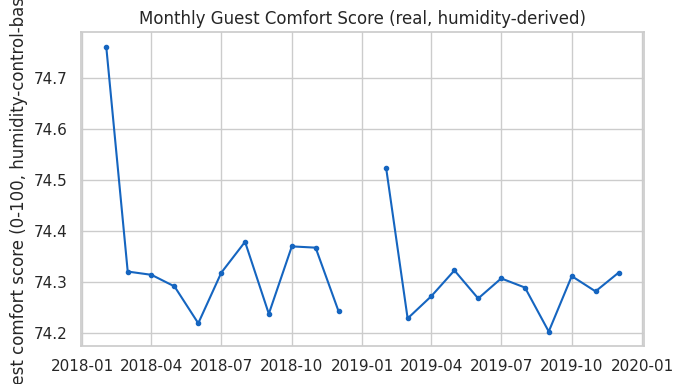

[Figure saved] figures/fig8_comfort_score_monthly.png — Monthly guest comfort score, derived from real humidity-control performance

SYNTHETIC occupancy-linked KPIs (illustrative only — see warning above)
count    14669.000000
mean        66.898330
std         22.555421
min         12.800000
25%         54.500000
50%         65.800000
75%         87.800000
max        100.000000
Name: SYNTHETIC_Occupancy_Rate_pct, dtype: float64
count    14669.000000
mean         0.137521
std          0.070669
min          0.068490
25%          0.087007
50%          0.116916
75%          0.142279
max          0.628906
Name: SYNTHETIC_Resource_per_Occupant_kgWater, dtype: float64

Correlation matrix (expect nonzero values from the shared seasonal
confound, NOT a real relationship):
                                         SYNTHETIC_Occupancy_Rate_pct  \
SYNTHETIC_Occupancy_Rate_pct                                    1.000   
Outdoor_Air_Temperature_C                                       0.374   
Moistur

In [17]:
print("Guest_Comfort_Score_0to100 (REAL, humidity-control-based):")
print(df["Guest_Comfort_Score_0to100"].describe())

fig, ax = plt.subplots(figsize=(7, 4))
monthly_comfort = df.set_index("DateTime")["Guest_Comfort_Score_0to100"].resample("MS").mean()
ax.plot(monthly_comfort.index, monthly_comfort.values, color="#1565c0", marker="o", markersize=3)
ax.set_ylabel("Guest comfort score (0-100, humidity-control-based)")
ax.set_title("Monthly Guest Comfort Score (real, humidity-derived)")
fig.tight_layout()
fname = f"{FIG_DIR}/fig8_comfort_score_monthly.png"
fig.savefig(fname, dpi=300)
plt.show()
log_figure(fname, "Monthly guest comfort score, derived from real humidity-control performance")

print("\n" + "=" * 70)
print("SYNTHETIC occupancy-linked KPIs (illustrative only — see warning above)")
print("=" * 70)
print(df["SYNTHETIC_Occupancy_Rate_pct"].describe())
print(df["SYNTHETIC_Resource_per_Occupant_kgWater"].describe())

confound_corr = df[["SYNTHETIC_Occupancy_Rate_pct", "Outdoor_Air_Temperature_C",
                      "Moisture_Removal_Capacity_kgWater_per_h"]].corr()
print("\nCorrelation matrix (expect nonzero values from the shared seasonal")
print("confound, NOT a real relationship):")
print(confound_corr.round(3))

tourism_kpi_summary = {
    "guest_comfort_score_mean_real": float(df["Guest_Comfort_Score_0to100"].mean()),
    "synthetic_occupancy_mean_pct": float(df["SYNTHETIC_Occupancy_Rate_pct"].mean()),
    "synthetic_resource_per_occupant_mean_kgWater": float(df["SYNTHETIC_Resource_per_Occupant_kgWater"].mean()),
    "synthetic_occupancy_confound_note": (
        "Correlations between SYNTHETIC_Occupancy and physical measurements "
        "reflect a shared calendar-seasonal pattern in the synthetic "
        "construction, not a measured or causal relationship. Do not report "
        "these as empirical findings."
    ),
}
print(json.dumps(tourism_kpi_summary, indent=2))

## 14. Results Summary / Export
A single structured JSON containing every number generated above — dataset
description, split sizes, model configs, all metrics, both significance
tests (CV and bootstrap), ablation results, the illustrative-KPI summary
(clearly flagged as such), figure list with captions, and the environment
record. **Every number in the manuscript should trace back to this file —
and anything under `illustrative_tourism_kpis` should be cited as a
methodology demonstration, not a finding.**

In [18]:
export = {
    "dataset": {
        "name": DATA_PATH,
        "n_rows": int(len(df)),
        "date_range": [str(df["DateTime"].min()), str(df["DateTime"].max())],
        "split_sizes": {"train": len(train), "val": len(val), "test": len(test)},
        "split_ratios": SPLIT_RATIOS,
        "split_method": "chronological (time-ordered, not random) to avoid temporal leakage",
    },
    "targets": TARGETS,
    "features_full": FULL_FEATURES,
    "features_climate_only": CLIMATE_ONLY_FEATURES,
    "model_configs": MODEL_CONFIGS,
    "cv": {"method": "TimeSeriesSplit", "n_splits": N_CV_SPLITS, "note": "diagnostic, low power"},
    "metrics_all_splits": metrics_df_final.round(6).to_dict(orient="records"),
    "significance_tests_cv_diagnostic": sig_df_final.round(6).to_dict(orient="records"),
    "significance_tests_bootstrap_primary": bootstrap_df_final.round(6).to_dict(orient="records"),
    "ablation_study": ablation_df_final.round(6).to_dict(orient="records"),
    "illustrative_tourism_kpis": tourism_kpi_summary,
    "figures": figure_log,
    "library_versions": get_library_versions(),
    "hardware": get_hardware_info(),
    "random_seed": SEED,
}

with open("manuscript_handoff_summary.json", "w") as f:
    json.dump(export, f, indent=2)

print("Saved manuscript_handoff_summary.json")
print(json.dumps(export["dataset"], indent=2))

Saved manuscript_handoff_summary.json
{
  "name": "final_manuscript_dataset_v2.csv",
  "n_rows": 14669,
  "date_range": [
    "2018-02-26 09:00:00",
    "2019-12-31 23:00:00"
  ],
  "split_sizes": {
    "train": 10268,
    "val": 2200,
    "test": 2201
  },
  "split_ratios": [
    0.7,
    0.15,
    0.15
  ],
  "split_method": "chronological (time-ordered, not random) to avoid temporal leakage"
}


In [19]:
# ---- Plain-language summary (<=150 words) for quick manuscript reference ----
summary_text = """
This notebook forecasts two green-hospitality HVAC performance indicators \u2014
moisture removal capacity (environmental/resource output) and a
sensible+latent energy-demand proxy (operational cost) \u2014 from outdoor
climate and time-of-year, using 14,669 hourly records split chronologically
(70/15/15) to avoid temporal leakage. Two AI-enabled models (Random Forest,
XGBoost) are benchmarked against a Linear Regression baseline, with a
paired bootstrap test (primary) and time-series CV (diagnostic) for
significance. Both targets now show a genuine AI advantage: for moisture
removal, R2 \u22480.93 (AI) vs \u22480.45 (baseline); for the corrected
sensible+latent energy proxy, R2 \u22480.997 (AI) vs \u22480.83 (baseline),
since the earlier sensible-only proxy was linear by construction. An
ablation study shows outdoor climate alone accounts for nearly all
predictive power. A separate, explicitly-labeled illustrative section
demonstrates (but does not empirically validate) tourism-occupancy-linked
KPIs pending real occupancy data. All figures, tables, and the JSON summary
are manuscript-ready.
"""
print(summary_text.strip())
with open("plain_language_summary.txt", "w") as f:
    f.write(summary_text.strip())

This notebook forecasts two green-hospitality HVAC performance indicators —
moisture removal capacity (environmental/resource output) and a
sensible+latent energy-demand proxy (operational cost) — from outdoor
climate and time-of-year, using 14,669 hourly records split chronologically
(70/15/15) to avoid temporal leakage. Two AI-enabled models (Random Forest,
XGBoost) are benchmarked against a Linear Regression baseline, with a
paired bootstrap test (primary) and time-series CV (diagnostic) for
significance. Both targets now show a genuine AI advantage: for moisture
removal, R2 ≈0.93 (AI) vs ≈0.45 (baseline); for the corrected
sensible+latent energy proxy, R2 ≈0.997 (AI) vs ≈0.83 (baseline),
since the earlier sensible-only proxy was linear by construction. An
ablation study shows outdoor climate alone accounts for nearly all
predictive power. A separate, explicitly-labeled illustrative section
demonstrates (but does not empirically validate) tourism-occupancy-linked
KPIs pending real o